In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("C:/Users/jsmvk/Desktop/SGH/Praca magisterska/south+german+credit+update/SouthGermanCredit.asc", sep = " ", engine = "python")

[Text(0, 0, '300'), Text(0, 0, '700')]

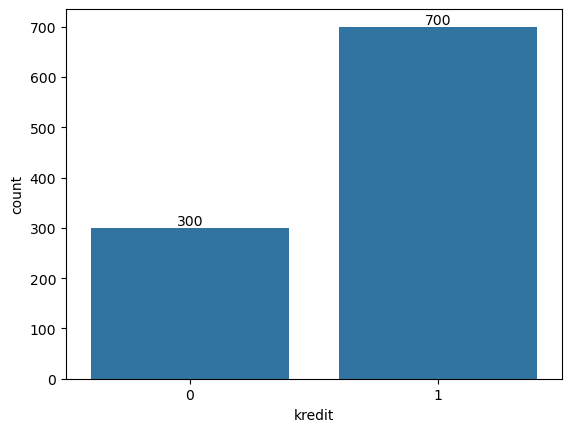

In [2]:
ax = sns.countplot(data = df, x = 'kredit')
ax.bar_label(ax.containers[0])

In [3]:
df['verw'].unique()

array([ 2,  0,  9,  3,  1, 10,  5,  4,  6,  8])

In [4]:
df['verw'] = df['verw'].replace(8, 7)
df['verw'] = df['verw'].replace(9, 8)
df['verw'] = df['verw'].replace(10, 9)

In [5]:
df['verw'].unique()

array([2, 0, 8, 3, 1, 9, 5, 4, 6, 7])

In [6]:
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata

In [7]:
metadata = Metadata.detect_from_dataframe(df)

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(df[df["kredit"] == 0])

synthetic_data_0 = synthesizer.sample(num_rows = 400)

C:\Users\jsmvk\anaconda3\Lib\site-packages\sdv\single_table\base.py:139: UserWarning:

We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.



In [8]:
len(synthetic_data_0[synthetic_data_0["kredit"] == 0])

400

In [9]:
df = pd.concat([synthetic_data_0, df], axis = 0)

In [10]:
df = df.sample(frac = 1).reset_index(drop = True)

In [11]:
mapping_colnames = {
    
    "laufkont":"stan_konta",
    "laufzeit":"czas_zapadalności_kredytu",
    "moral":"historia_kredytowa",
    "verw":"cel_kredytu",
    "hoehe":"wielkość_kredytu",
    "sparkont":"oszczędności",
    "beszeit":"czas_zatrudnienia",
    "rate":"wysokość_raty_kredytu",
    "famges":"status_matrymonialny",
    "buerge":"inni_kredytobiorcy",
    "wohnzeit":"miejsce_zamieszkania",
    "verm":"najdroższa_własność",
    "alter":"wiek",
    "weitkred":"inne_kredyty",
    "wohn":"sposób_opłaty_mieszkania",
    "bishkred":"liczba_kredytów_w_historii",
    "beruf":"praca",
    "pers":"liczba_osób_na_utrzymaniu",
    "telef":"telefon",
    "gastarb":"cudzoziemiec",
    "kredit":"ryzyko_kredytowe"
    
}

In [12]:
df.rename(columns = mapping_colnames, inplace = True)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_opłaty_miesz

In [14]:
df['cel_kredytu'].unique()

array([2, 3, 8, 0, 6, 1, 9, 4, 5, 7])

In [15]:
df['wielkość kredytu / czas spłaty'] = df['wielkość_kredytu'] / df['czas_zapadalności_kredytu']

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   int64  
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   int64  
 3   cel_kredytu                     1400 non-null   int64  
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   int64  
 6   czas_zatrudnienia               1400 non-null   int64  
 7   wysokość_raty_kredytu           1400 non-null   int64  
 8   status_matrymonialny            1400 non-null   int64  
 9   inni_kredytobiorcy              1400 non-null   int64  
 10  miejsce_zamieszkania            1400 non-null   int64  
 11  najdroższa_własność             1400 non-null   int64  
 12  wiek                            1400 non-null

In [17]:
#mapping_colnames = dict(np.array(credit_approval.variables[["name", "description"]]))

In [18]:
#df.rename(columns = mapping_colnames, inplace = True)
#df.rename(columns = {'1 = Good, 0 = Bad' : 'class'}, inplace = True)

In [19]:
#df.info()

In [20]:
df.describe(exclude = "object")

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,...,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,2.392857,21.974286,2.455000,2.654286,3510.215000,1.989286,3.355000,2.997143,2.660714,1.141429,...,34.707857,2.633571,1.922857,1.388571,2.921429,1.850000,1.391429,1.966429,0.500000,170.550478
std,1.249425,12.237029,1.090332,2.514387,3027.386561,1.533714,1.220672,1.120346,0.727210,0.461527,...,11.446601,0.738516,0.546395,0.567538,0.657805,0.357199,0.488244,0.180188,0.500179,153.275349
min,1.000000,4.000000,0.000000,0.000000,250.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,19.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,12.085106
25%,1.000000,12.000000,2.000000,0.000000,1375.500000,1.000000,2.750000,2.000000,2.000000,1.000000,...,26.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000,83.876894
50%,2.000000,18.000000,2.000000,2.000000,2448.000000,1.000000,3.000000,3.000000,3.000000,1.000000,...,32.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.500000,130.807143
75%,4.000000,29.000000,4.000000,3.000000,4591.750000,3.000000,5.000000,4.000000,3.000000,1.000000,...,41.000000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,214.791667
max,4.000000,72.000000,4.000000,9.000000,18424.000000,5.000000,5.000000,4.000000,4.000000,3.000000,...,75.000000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000,2482.666667


In [21]:
def describe_advanced(data):
    
    data = np.asarray(data)
    
    return {
        "max": np.max(data),
        "min": np.min(data),
        "dominanta": stats.mode(data).mode[0],
        "kurtoza": np.round(stats.kurtosis(data), 2),
        "skośność": np.round(stats.skew(data), 2),
        "średnia": np.round(np.mean(data), 2),
        "odchylenie standardowe": np.round(np.std(data), 2),
        "współczynnik zmienności": np.round(np.round(np.std(data), 2) / np.round(np.mean(data), 2), 2)
    }

In [22]:
num_cols = ['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek', 'wielkość kredytu / czas spłaty']

In [23]:
cat_cols = []

for i in df.columns:
    if i not in num_cols:
        cat_cols.append(i)

In [24]:
cat_cols.remove("ryzyko_kredytowe")
df[cat_cols] = df[cat_cols].astype("object")

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   object 
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   object 
 3   cel_kredytu                     1400 non-null   object 
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   object 
 6   czas_zatrudnienia               1400 non-null   object 
 7   wysokość_raty_kredytu           1400 non-null   object 
 8   status_matrymonialny            1400 non-null   object 
 9   inni_kredytobiorcy              1400 non-null   object 
 10  miejsce_zamieszkania            1400 non-null   object 
 11  najdroższa_własność             1400 non-null   object 
 12  wiek                            1400 non-null

[Text(0, 0, '700'), Text(0, 0, '700')]

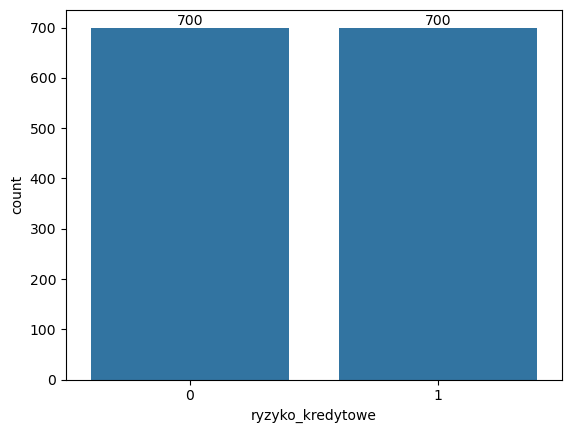

In [26]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [27]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(df[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [28]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,72.000000,4.000000,12.0,[0.62],[0.99],21.97,12.23,0.56
wielkość_kredytu,18424.000000,250.000000,781.0,[2.99],[1.7],3510.22,3026.31,0.86
wiek,75.000000,19.000000,23.0,[0.47],[0.99],34.71,11.44,0.33
wielkość kredytu / czas spłaty,2482.666667,12.085106,229.0,[73.19],[6.06],170.55,153.22,0.90


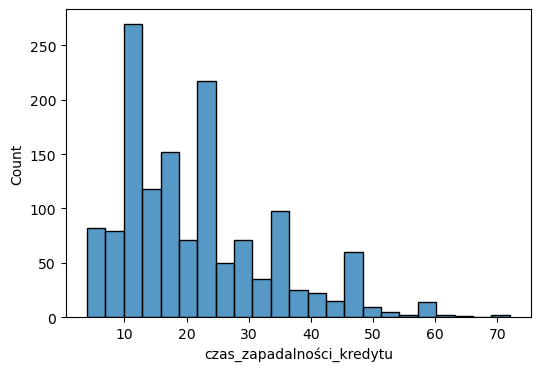

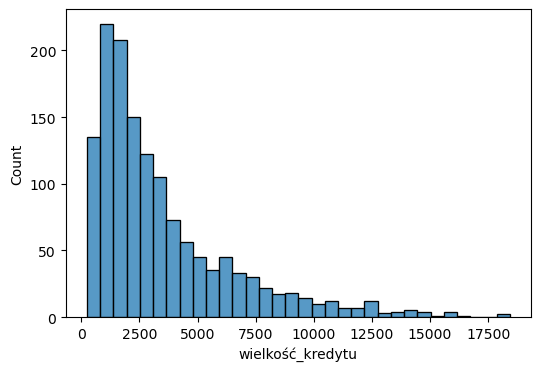

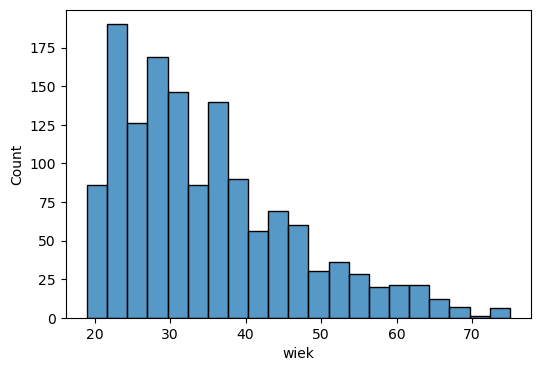

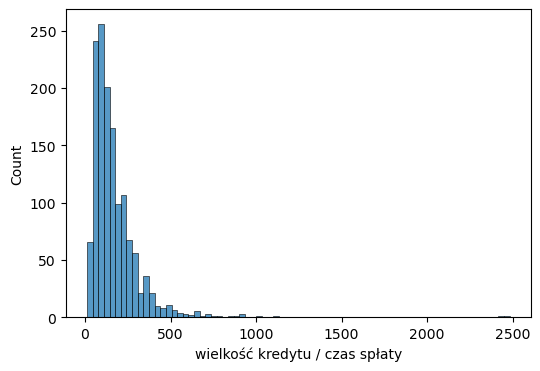

In [29]:
for i in num_cols:
     plt.figure(figsize=(6, 4))
     histograms = sns.histplot(df[i])
     plt.show()

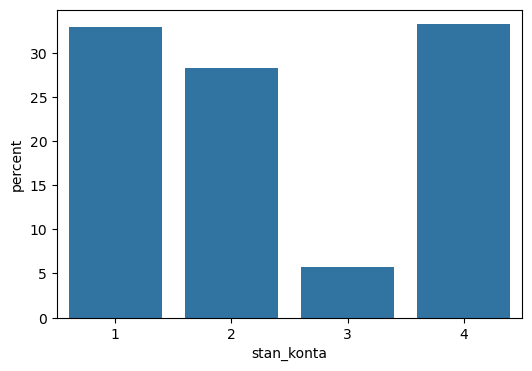

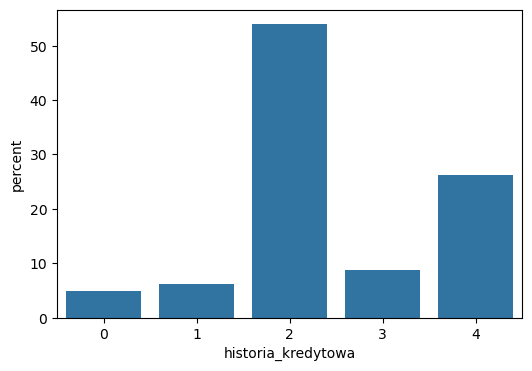

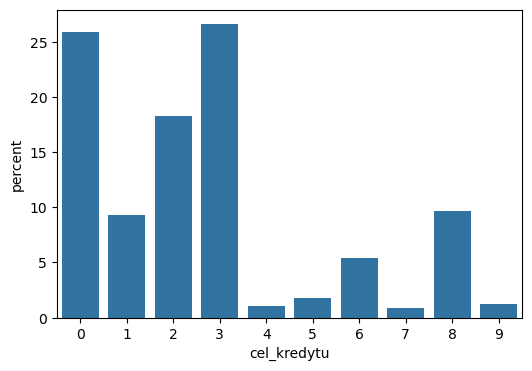

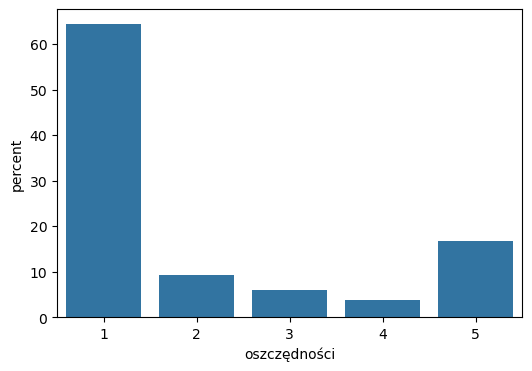

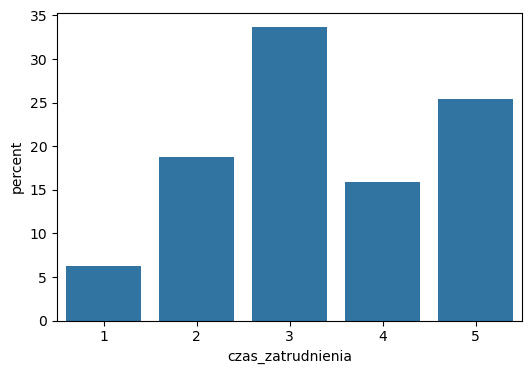

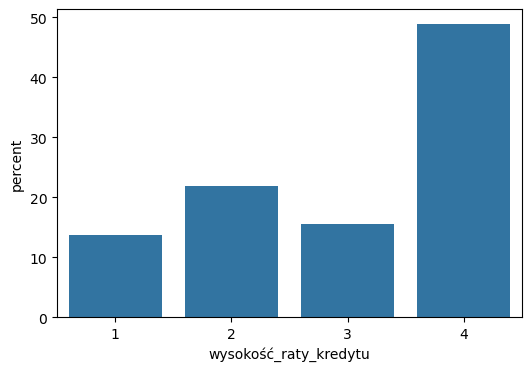

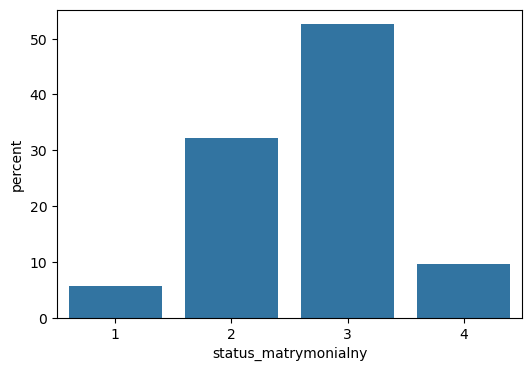

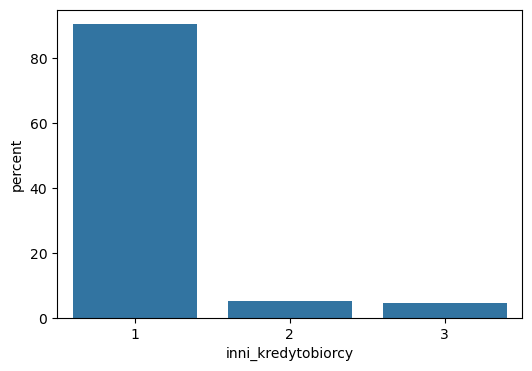

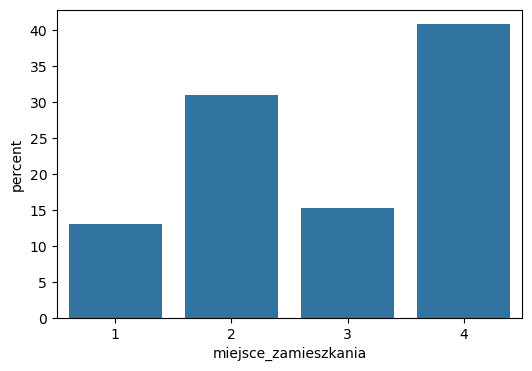

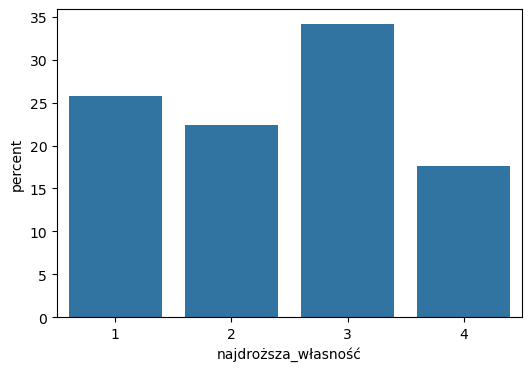

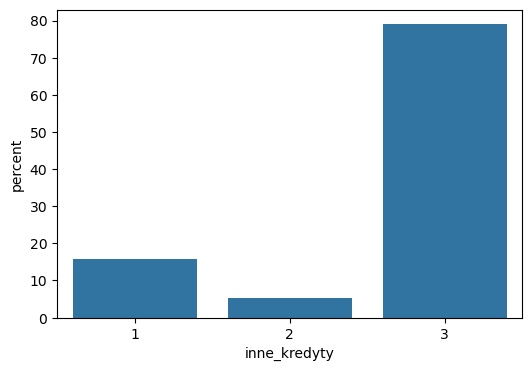

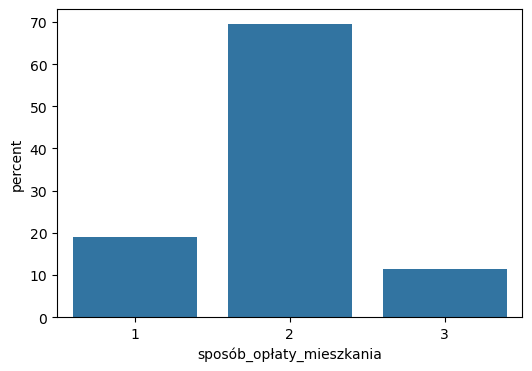

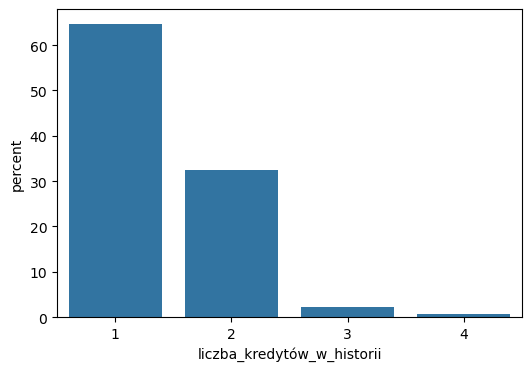

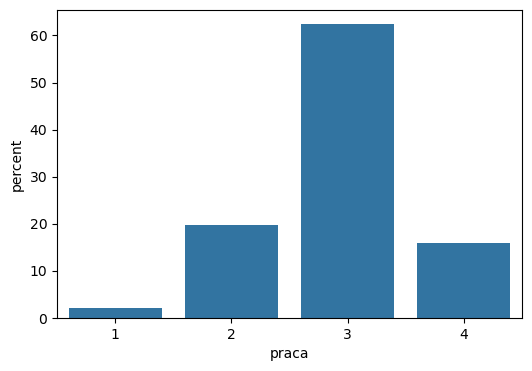

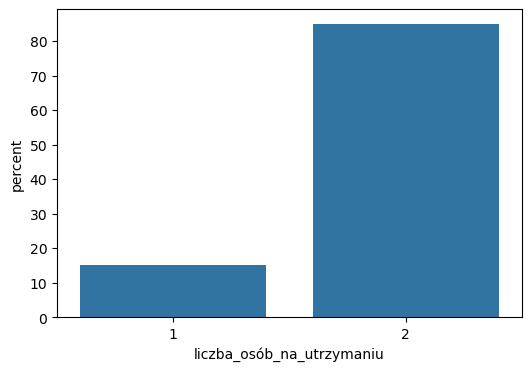

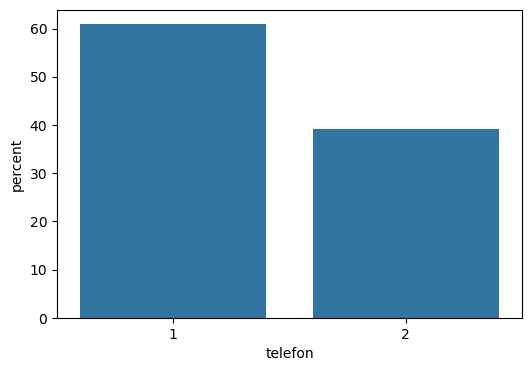

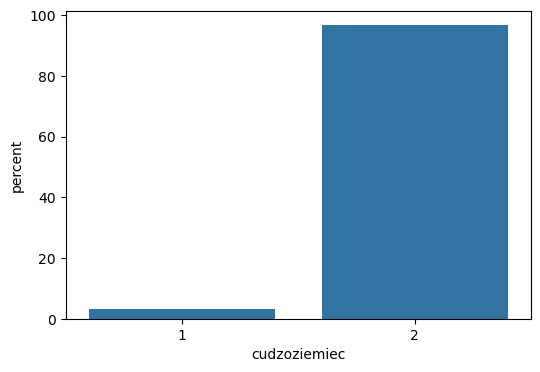

In [30]:
for i in cat_cols:
     plt.figure(figsize=(6, 4))
     countplots = sns.countplot(x = df[i], stat = "percent")
     plt.show()

In [31]:
scores = []

for i in cat_cols:
        name = i
        percent = df[i].value_counts() / len(df) * 100
        
        for category, percent in percent.items():
            scores.append({
                "Variable" : i,
                "Category": category,
                "Percent": percent
            })

In [32]:
scores = pd.DataFrame(scores)

In [33]:
scores.set_index("Variable", inplace = True)

In [34]:
scores.sort_values(by = ["Variable", "Category"], inplace = True)

In [35]:
print(scores.to_string())

                            Category    Percent
Variable                                       
cel_kredytu                        0  25.857143
cel_kredytu                        1   9.285714
cel_kredytu                        2  18.285714
cel_kredytu                        3  26.571429
cel_kredytu                        4   1.071429
cel_kredytu                        5   1.785714
cel_kredytu                        6   5.428571
cel_kredytu                        7   0.857143
cel_kredytu                        8   9.642857
cel_kredytu                        9   1.214286
cudzoziemiec                       1   3.357143
cudzoziemiec                       2  96.642857
czas_zatrudnienia                  1   6.285714
czas_zatrudnienia                  2  18.714286
czas_zatrudnienia                  3  33.642857
czas_zatrudnienia                  4  15.928571
czas_zatrudnienia                  5  25.428571
historia_kredytowa                 0   4.857143
historia_kredytowa                 1   6

In [36]:
scores["Percent"].sum()

np.float64(1699.9999999999998)

<Axes: >

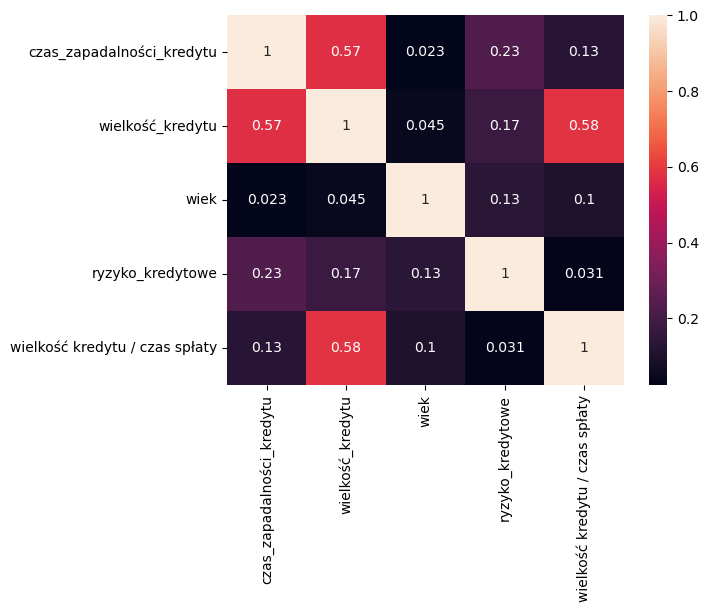

In [37]:
sns.heatmap(df.corr(numeric_only = True).abs(), annot = True)

In [38]:
#df.drop("Duration", axis = 1, inplace = True)

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1400 non-null   object 
 1   czas_zapadalności_kredytu       1400 non-null   int64  
 2   historia_kredytowa              1400 non-null   object 
 3   cel_kredytu                     1400 non-null   object 
 4   wielkość_kredytu                1400 non-null   int64  
 5   oszczędności                    1400 non-null   object 
 6   czas_zatrudnienia               1400 non-null   object 
 7   wysokość_raty_kredytu           1400 non-null   object 
 8   status_matrymonialny            1400 non-null   object 
 9   inni_kredytobiorcy              1400 non-null   object 
 10  miejsce_zamieszkania            1400 non-null   object 
 11  najdroższa_własność             1400 non-null   object 
 12  wiek                            1400 non-null

In [40]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
0,1,31,1,2,4489,1,3,4,3,1,...,24,3,2,1,4,2,2,2,0,144.806452
1,1,31,2,2,3282,3,5,4,1,1,...,28,3,1,1,3,2,1,1,0,105.870968
2,4,24,2,3,3430,3,5,3,3,1,...,31,3,2,1,3,1,2,2,1,142.916667
3,4,9,2,2,1388,1,3,4,2,1,...,26,3,1,1,3,2,1,2,1,154.222222
4,4,30,2,8,1955,1,3,4,3,1,...,30,3,2,2,2,1,2,2,0,65.166667


In [41]:
from sklearn.preprocessing import OneHotEncoder

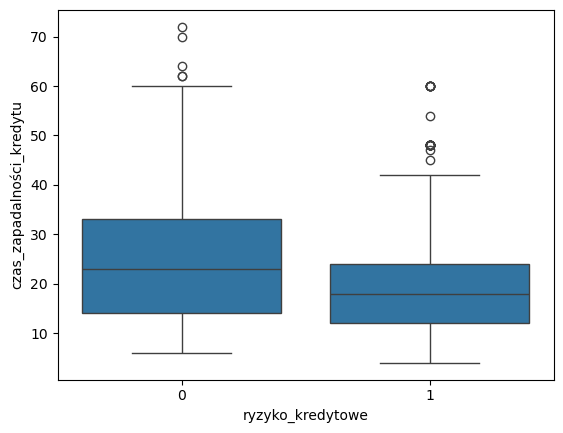

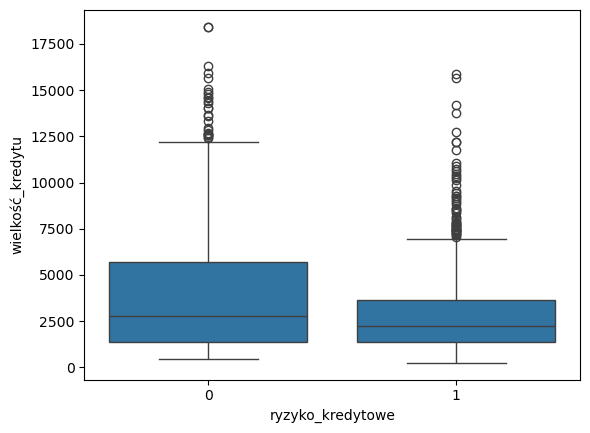

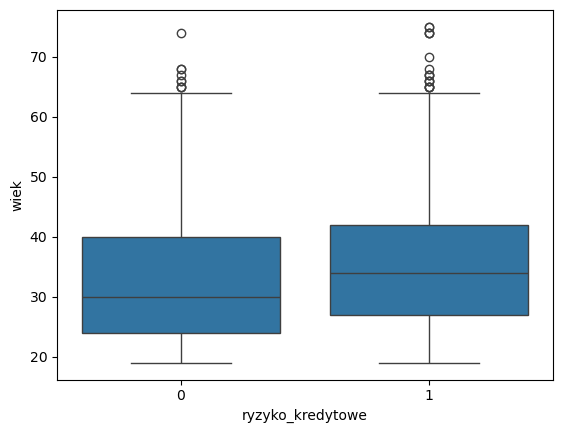

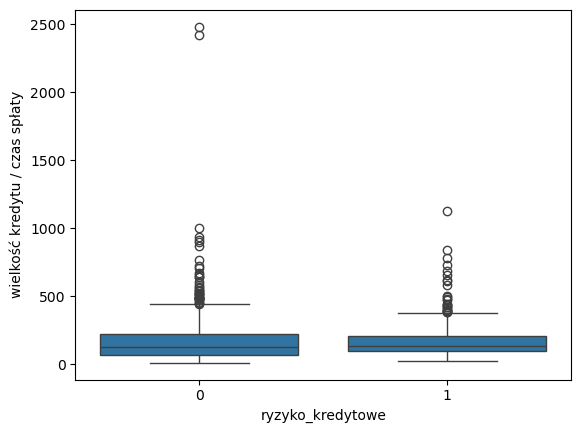

In [42]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [43]:
for i in num_cols:
    q_treshold = df[i].quantile(0.99)
    df = df[df[i] <= q_treshold]

In [44]:
num_cols

['czas_zapadalności_kredytu',
 'wielkość_kredytu',
 'wiek',
 'wielkość kredytu / czas spłaty']

In [45]:
cat_cols

['stan_konta',
 'historia_kredytowa',
 'cel_kredytu',
 'oszczędności',
 'czas_zatrudnienia',
 'wysokość_raty_kredytu',
 'status_matrymonialny',
 'inni_kredytobiorcy',
 'miejsce_zamieszkania',
 'najdroższa_własność',
 'inne_kredyty',
 'sposób_opłaty_mieszkania',
 'liczba_kredytów_w_historii',
 'praca',
 'liczba_osób_na_utrzymaniu',
 'telefon',
 'cudzoziemiec']

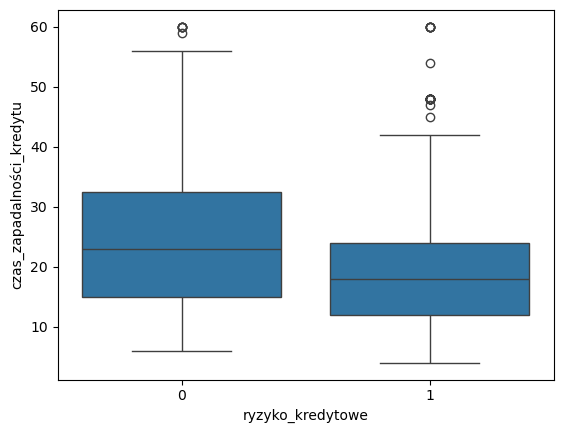

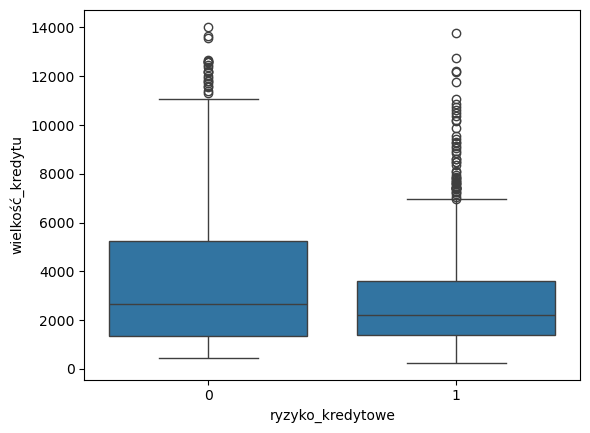

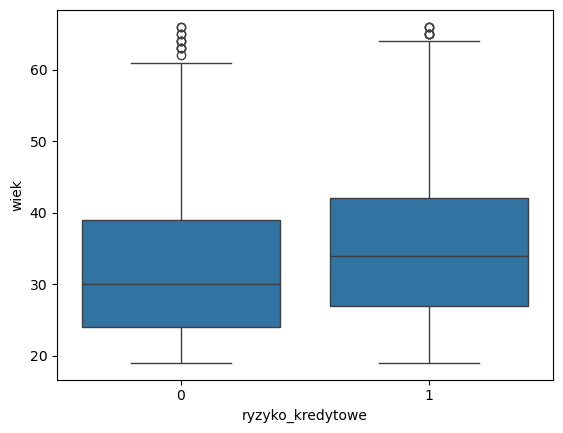

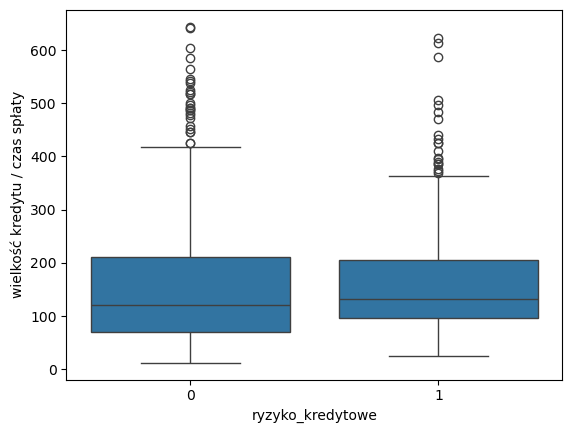

In [46]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [47]:
df.info()

<class 'pandas.DataFrame'>
Index: 1354 entries, 0 to 1399
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1354 non-null   object 
 1   czas_zapadalności_kredytu       1354 non-null   int64  
 2   historia_kredytowa              1354 non-null   object 
 3   cel_kredytu                     1354 non-null   object 
 4   wielkość_kredytu                1354 non-null   int64  
 5   oszczędności                    1354 non-null   object 
 6   czas_zatrudnienia               1354 non-null   object 
 7   wysokość_raty_kredytu           1354 non-null   object 
 8   status_matrymonialny            1354 non-null   object 
 9   inni_kredytobiorcy              1354 non-null   object 
 10  miejsce_zamieszkania            1354 non-null   object 
 11  najdroższa_własność             1354 non-null   object 
 12  wiek                            1354 non-null   in

In [48]:
sum(df.duplicated())

0

In [49]:
df.reset_index(inplace = True, drop = True)

In [50]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe,wielkość kredytu / czas spłaty
0,1,31,1,2,4489,1,3,4,3,1,...,24,3,2,1,4,2,2,2,0,144.806452
1,1,31,2,2,3282,3,5,4,1,1,...,28,3,1,1,3,2,1,1,0,105.870968
2,4,24,2,3,3430,3,5,3,3,1,...,31,3,2,1,3,1,2,2,1,142.916667
3,4,9,2,2,1388,1,3,4,2,1,...,26,3,1,1,3,2,1,2,1,154.222222
4,4,30,2,8,1955,1,3,4,3,1,...,30,3,2,2,2,1,2,2,0,65.166667


In [51]:
from sklearn.model_selection import train_test_split

X = df.drop("ryzyko_kredytowe", axis = 1)
y = df["ryzyko_kredytowe"]

[Text(0, 0, '671'), Text(0, 0, '683')]

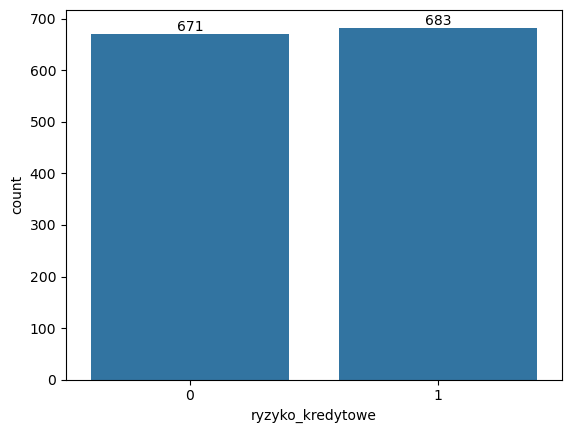

In [52]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [53]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1354 entries, 0 to 1353
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1354 non-null   object 
 1   czas_zapadalności_kredytu       1354 non-null   int64  
 2   historia_kredytowa              1354 non-null   object 
 3   cel_kredytu                     1354 non-null   object 
 4   wielkość_kredytu                1354 non-null   int64  
 5   oszczędności                    1354 non-null   object 
 6   czas_zatrudnienia               1354 non-null   object 
 7   wysokość_raty_kredytu           1354 non-null   object 
 8   status_matrymonialny            1354 non-null   object 
 9   inni_kredytobiorcy              1354 non-null   object 
 10  miejsce_zamieszkania            1354 non-null   object 
 11  najdroższa_własność             1354 non-null   object 
 12  wiek                            1354 non-null

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [55]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(X_train[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [56]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,60.000000,4.000000,12.0,[0.29],[0.89],21.79,11.84,0.54
wielkość_kredytu,14027.000000,250.000000,1082.0,[1.82],[1.46],3272.23,2659.23,0.81
wiek,66.000000,19.000000,27.0,[0.11],[0.88],34.34,10.87,0.32
wielkość kredytu / czas spłaty,641.285714,12.085106,41.0,[2.34],[1.4],154.68,98.59,0.64


In [57]:
pos_label, neg_label = 1, 0

In [58]:
#from imblearn.over_sampling import SMOTE

In [59]:
from sklearn.preprocessing import StandardScaler

In [60]:
from sklearn.linear_model import LogisticRegression

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

In [62]:
from sklearn.compose import ColumnTransformer

def transform_data(X_train, num_cols, cat_cols, ttype):
    num_transformer = StandardScaler()

    cat_transformer = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    if ttype == 'all':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'cat':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'num':
         preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', 'passthrough', cat_cols)
            ],
            remainder='drop'
        )
    else:
        print("wrong param")
    
    X_train_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()
    
    X_train = pd.DataFrame(
        X_train_transformed, 
        columns = feature_names, 
        index = X_train.index
    )
    
    return preprocessor

In [63]:
def united_shapley(shap_ohe):
    feature_groups = {}
    
    for i in df.columns:
        div_columns = [j[5:] for j in X_train_transformed_df.columns if j[5:].startswith(i)]
        feature_groups[i] = div_columns
    
    if shap_ohe.values.ndim == 3:
        current_values = shap_ohe.values[:, :, 1].copy()
        current_base_values = shap_ohe.base_values[:, 1].copy()
    elif shap_ohe.values.ndim == 2:
        current_values = shap_ohe.values.copy()
        current_base_values = shap_ohe.base_values.copy()
    
    current_feature_names = [
        name[5:] if name.startswith(('num__', 'cat__')) else name 
        for name in shap_ohe.feature_names
    ]
    
    for group_name, sum_columns in feature_groups.items():
        indx = [current_feature_names.index(c) for c in sum_columns if c in current_feature_names]
    
        if indx:
            sum_shap = current_values[:, indx].sum(axis = 1)
    
            for i in sorted(indx, reverse = True):
                current_values = np.delete(current_values, i, axis = 1)
                current_feature_names.pop(i)
    
            current_values = np.c_[current_values, sum_shap]
            current_feature_names.append(group_name)
    
    new_shap_values = shap.Explanation(
            values = current_values,
            base_values = current_base_values,
            data =  X_train.values,
            feature_names = current_feature_names
        )
    
    return new_shap_values

In [64]:
#https://medium.com/@ravi.abhinav4/improving-class-imbalance-with-class-weights-in-machine-learning-af072fdd4aa4
def calculate_class_weights(y):
    unique_classes, class_counts = np.unique(y, return_counts=True)
    total_samples = len(y)
    class_weights = {}

    for class_label, class_counts in zip(unique_classes, class_counts):
        class_weight = total_samples / (2.0 * class_counts)
        class_weights[class_label] = class_weight

    class_weight0 = class_weights[0]
    class_weight1 = class_weights[1]

    print(f'Weight for class 0: ', class_weight0)
    print(f'Weight for class 1: ', class_weight1)

In [65]:
calculate_class_weights(y)

Weight for class 0:  1.0089418777943369
Weight for class 1:  0.9912152269399708


In [66]:
class_weights = {0: 1.7017543859649122, 1: 0.708029197080292}

In [67]:
from sklearn.model_selection import LearningCurveDisplay, RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 10, random_state = 42)

In [68]:
from sklearn.model_selection import TunedThresholdClassifierCV

In [69]:
from imblearn.pipeline import Pipeline

In [70]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from sklearn.model_selection import ShuffleSplit

def lower_bound(cv_results):
    best_score_idx = np.argmax(cv_results["mean_test_neg_brier_score"])
    return (
        cv_results["mean_test_neg_brier_score"][best_score_idx]
        - cv_results["std_test_neg_brier_score"][best_score_idx])

def best_low_complexity(cv_results):
    threshold = lower_bound(cv_results)
    candidate_idx = np.flatnonzero(cv_results["mean_test_neg_brier_score"] >= threshold)
    best_idx = candidate_idx[
        cv_results["param_reduce_dim__n_components"][candidate_idx].argmin()
    ]
    return best_idx

In [71]:
from sklearn.metrics import confusion_matrix

def fpr_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    tn, fp, _, _ = cm.ravel()
    tnr = tn / (tn + fp)
    return 1 - tnr

In [72]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score

tpr_score = recall_score  # TPR and recall are the same metric
scr = {
    "precision": make_scorer(precision_score, pos_label=pos_label, zero_division = 0),
    "recall": make_scorer(recall_score, pos_label=pos_label),
    "bad_recall" : make_scorer(recall_score, pos_label=pos_label, zero_division=0),
    "fpr": make_scorer(fpr_score, neg_label=neg_label, pos_label=pos_label,  greater_is_better = False),
    "tpr": make_scorer(tpr_score, pos_label=pos_label),
    'accuracy': make_scorer(accuracy_score, neg_label=neg_label, pos_label=pos_label)
}

In [73]:
import numpy as np

def credit_gain_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])

    gain_matrix = np.array(
        [
            [0, -1],
            [-5, 0],
        ]
    )
    return np.sum(cm * gain_matrix)


scr["credit_gain"] = make_scorer(
    credit_gain_score, neg_label=neg_label, pos_label=pos_label
)

In [74]:
lr = LogisticRegression(random_state = 42, class_weight = "balanced")

In [75]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 1083 entries, 230 to 1237
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stan_konta                      1083 non-null   object 
 1   czas_zapadalności_kredytu       1083 non-null   int64  
 2   historia_kredytowa              1083 non-null   object 
 3   cel_kredytu                     1083 non-null   object 
 4   wielkość_kredytu                1083 non-null   int64  
 5   oszczędności                    1083 non-null   object 
 6   czas_zatrudnienia               1083 non-null   object 
 7   wysokość_raty_kredytu           1083 non-null   object 
 8   status_matrymonialny            1083 non-null   object 
 9   inni_kredytobiorcy              1083 non-null   object 
 10  miejsce_zamieszkania            1083 non-null   object 
 11  najdroższa_własność             1083 non-null   object 
 12  wiek                            1083 non-null   

In [76]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import FixedThresholdClassifier

clf_lr = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LogisticRegression(random_state = 42, class_weight = "balanced"))])

In [77]:
from scipy.stats import randint, loguniform

param_distributions = [{'classifier__C': loguniform(1e-5, 0.01),
               'classifier__solver': ['liblinear'],
               'classifier__max_iter' : [1000, 1500]}]

In [78]:
from sklearn.metrics import fbeta_score

In [79]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

model = RandomizedSearchCV(clf_lr, 
                           param_distributions = param_distributions, 
                           cv = cv, 
                           n_jobs = 1, 
                           refit = 'recall', 
                           n_iter = 10, 
                           scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                           return_train_score = True, 
                           random_state = 42)

In [80]:
model.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier__C': <scipy.stats....0025FC7ED5BE0>, 'classifier__max_iter': [1000, 1500], 'classifier__solver': ['liblinear']}]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that

In [81]:
best_model = model.best_estimator_

In [82]:
results = pd.DataFrame(model.cv_results_)

In [83]:
from sklearn.metrics import PrecisionRecallDisplay, auc, precision_recall_curve, f1_score

In [84]:
def cv_cm(cv_object, y_train):
    total_train_obs = y_train.shape[0]
    cv_results = pd.DataFrame(cv_object.cv_results_)
    best_estimator_results = cv_results.iloc[cv_results['mean_test_recall'].idxmax(), :]

    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    true_positives = ((precision * recall) * (total_train_obs - (accuracy * total_train_obs))) / (recall - (2 * recall * precision) + precision)
    false_positives = round((true_positives - (precision * true_positives)) / precision, 0)
    false_negatives = round((true_positives - (recall * true_positives)) / recall, 0)

    print(f'accuracy: ', accuracy)
    print(f'recall: ', recall)
    print(f'precision: ', precision)
    
    true_negatives = round((accuracy * total_train_obs) - true_positives, 0)
    true_positives = round(true_positives, 0)

    prediction_list = [true_negatives, false_positives, false_negatives, true_positives]
    prediction_matrix = np.array(prediction_list).reshape(2, 2)

    plt.figure(figsize = (5, 4))
    ax = sns.heatmap(prediction_matrix, vmin = 0, vmax = total_train_obs, annot = True,
                    cmap = sns.color_palette('Spectral', as_cmap = True), fmt = 'g')
    plt.title('Confusion Matrix', fontsize = 16)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    return plt.show()
    return cv_results

accuracy:  0.6868830005120329
recall:  0.6937731442869057
precision:  0.6888493724481002


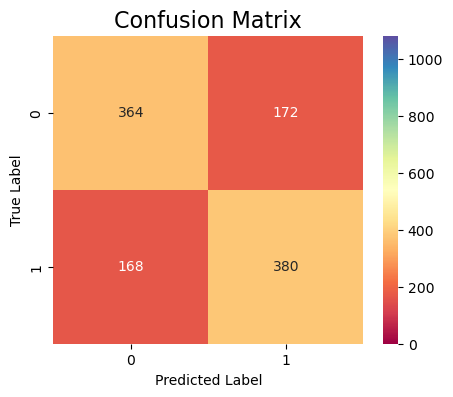

In [85]:
cv_cm(model, y_train)

In [86]:
#https://stackoverflow.com/questions/73582838/what-is-predict-proba-and-1-after-x-test-in-code
#column index 0 => negative class predictions
#column index 1 => positive class predictions

def set_threshold(chosen_model):
    y_scores = chosen_model.predict_proba(X_test)[:, 1]
    
    precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
    auc_score = auc(recall, precision)
    
    with np.errstate(divide='ignore', invalid='ignore'):
        f1s = 2 * (precision * recall) / (precision + recall)
        f1s[np.isnan(f1s)] = 0  
    
    best_thresh = thresholds[f1s.argmax()]
    print("Best threshold:", best_thresh)
    
    y_pred_reg_opt = (y_scores >= best_thresh).astype(int)
    return y_pred_reg_opt

In [87]:
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import cross_validate

def roc_cv(best_model):
    n_splits = 5
    cv = 5
    cv_results = cross_validate(
        best_model, X, y, cv=cv, return_estimator=True, return_indices=True
    )
    
    prop_cycle = plt.rcParams["axes.prop_cycle"]
    colors = prop_cycle.by_key()["color"]
    curve_kwargs_list = [
        dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
    ]
    names = [f"ROC fold {idx}" for idx in range(n_splits)]
    
    mean_fpr = np.linspace(0, 1, 100)
    interp_tprs = []
    
    _, ax = plt.subplots(figsize=(6, 6))
    viz = RocCurveDisplay.from_cv_results(
        cv_results,
        X,
        y,
        ax=ax,
        name=names,
        curve_kwargs=curve_kwargs_list,
        plot_chance_level=True,
    )
    
    for idx in range(n_splits):
        interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
        interp_tpr[0] = 0.0
        interp_tprs.append(interp_tpr)
    
    mean_tpr = np.mean(interp_tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(viz.roc_auc)
    
    ax.plot(
        mean_fpr,
        mean_tpr,
        color="b",
        label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
        lw=2,
        alpha=0.8,
    )
    
    std_tpr = np.std(interp_tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax.fill_between(
        mean_fpr,
        tprs_lower,
        tprs_upper,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )
    
    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate"
    )
    ax.legend(loc="lower right")
    plt.show()

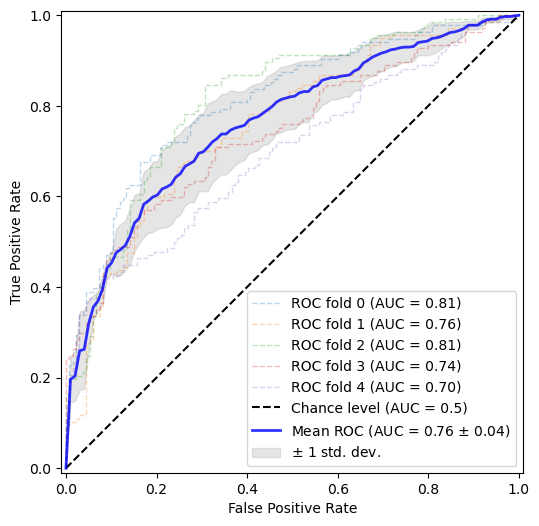

In [88]:
roc_cv(best_model)

In [89]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

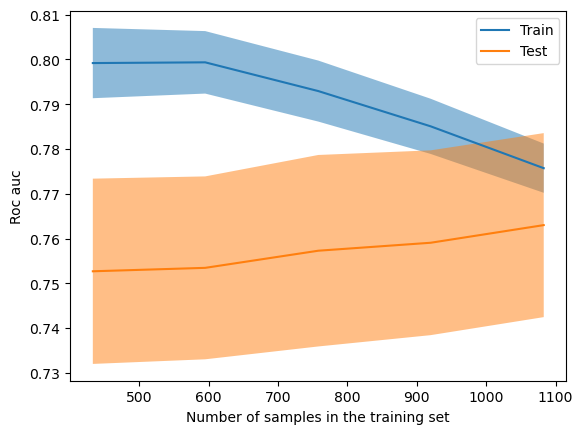

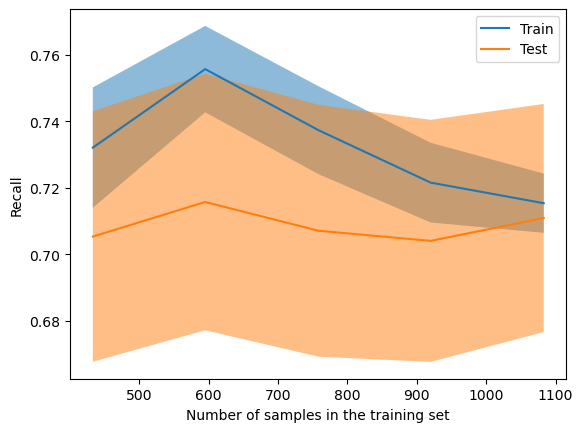

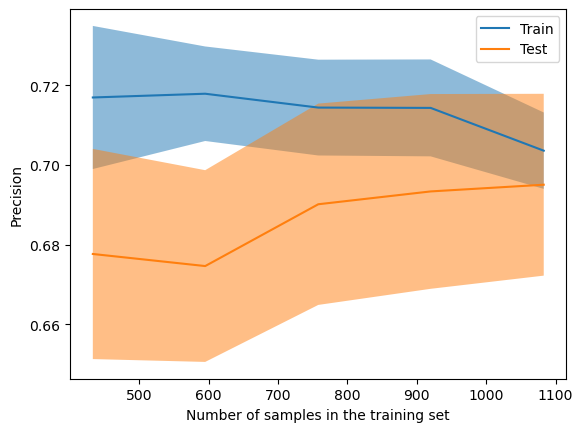

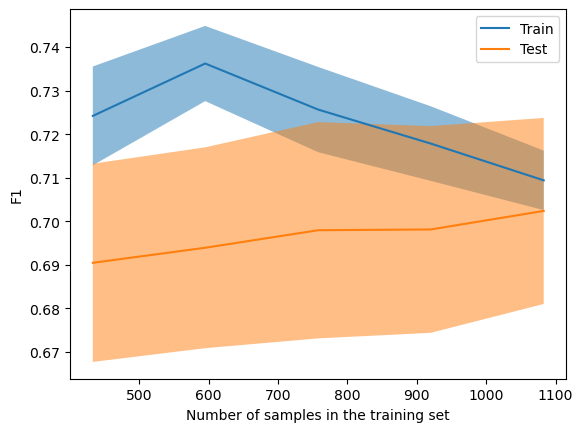

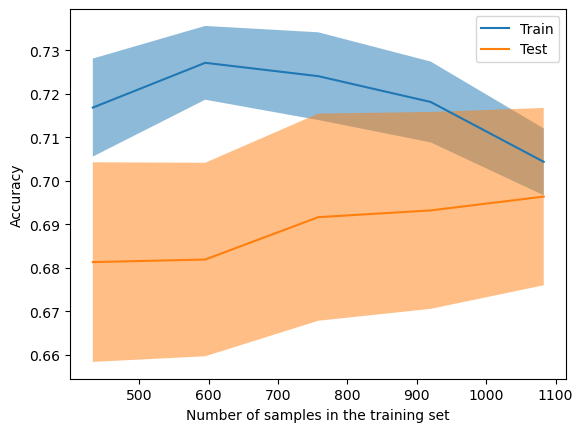

In [90]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_model, X, y, scoring = i, cv = cv, train_sizes = train_sizes, error_score = "raise")

In [91]:
from sklearn.model_selection import cross_val_score

def model_evaluation(estimator):

    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats = 5, random_state=42)
    metrics = {"accuracy", "roc_auc", "f1", "precision", "recall"}
    
    for i in metrics:
        scores = cross_val_score(estimator, X, y, scoring=i, cv=cv)
        
        print("Mean " + i + ":", scores.mean())
        print("Standard deviation:", scores.std())
        print("\n")

In [92]:
model_evaluation(best_model)

Mean roc_auc: 0.7633656705737095
Standard deviation: 0.02056914072118962


Mean recall: 0.7100966079862603
Standard deviation: 0.03330740682896956


Mean precision: 0.6957897670051615
Standard deviation: 0.023095431759600552


Mean f1: 0.7023980161044209
Standard deviation: 0.021732216048007506


Mean accuracy: 0.6967445674456744
Standard deviation: 0.020991454319347364




In [93]:
import shap

In [94]:
best_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [95]:
best_model = best_model.named_steps['classifier']

In [96]:
fitted_preprocessor = clf_lr.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [97]:
explainer = shap.Explainer(best_model, X_train_transformed_df, model_output = 'probability')
shap_values_ohe = explainer(X_train_transformed_df)
shap_values = united_shapley(shap_values_ohe)

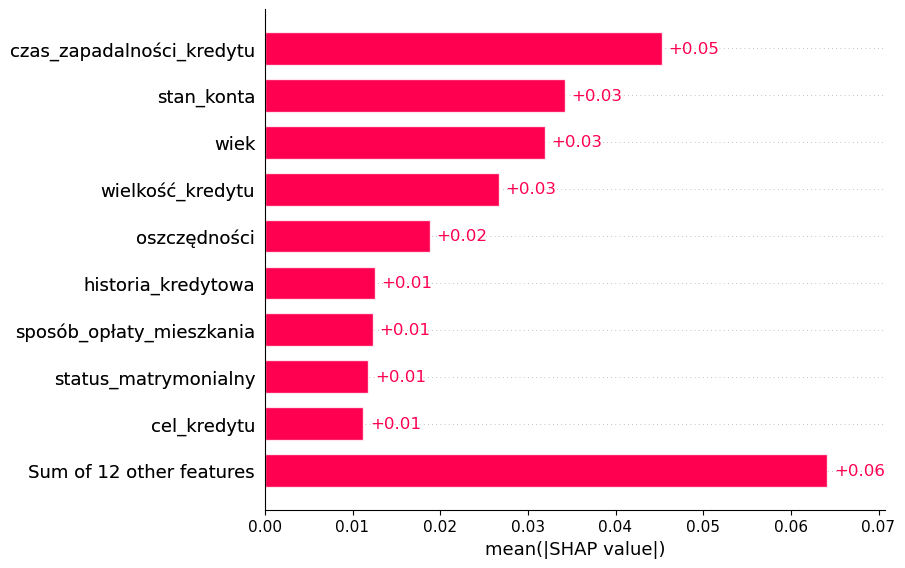

In [98]:
shap.plots.bar(shap_values)

In [99]:
X_train.head(1)

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,wielkość kredytu / czas spłaty
230,3,16,2,0,556,1,3,4,2,2,...,3,22,3,2,1,3,2,2,2,34.75


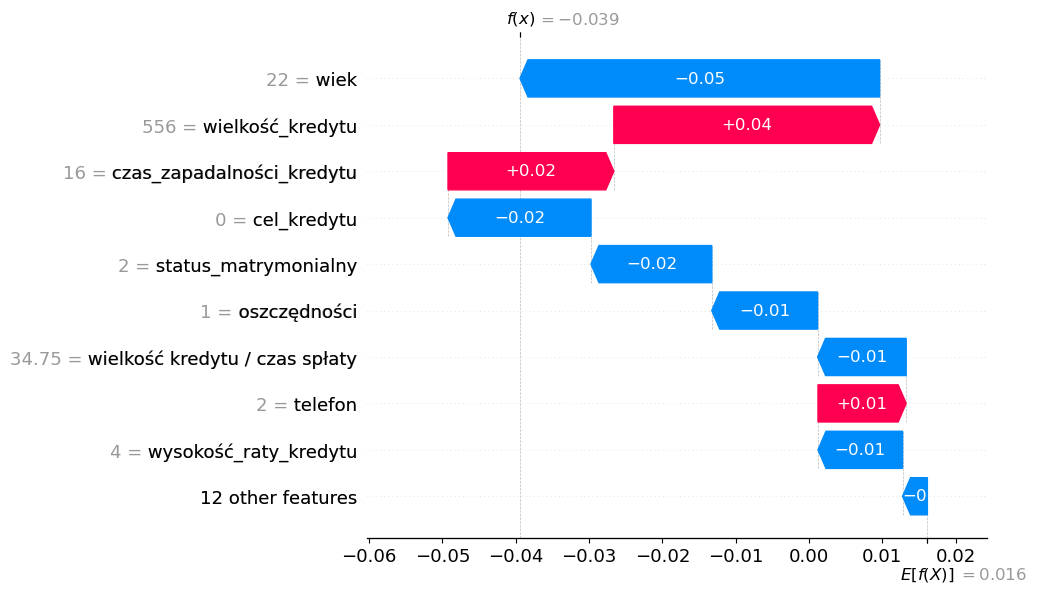

In [100]:
shap.plots.waterfall(shap_values[0], max_display=10, show=True)

In [101]:
from sklearn.metrics import brier_score_loss

In [102]:
y_scores = best_model.predict_proba(X_test_transformed)[:, 1]

In [103]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.2375350850425845

In [104]:
y_predicted = best_model.predict(X_test_transformed)

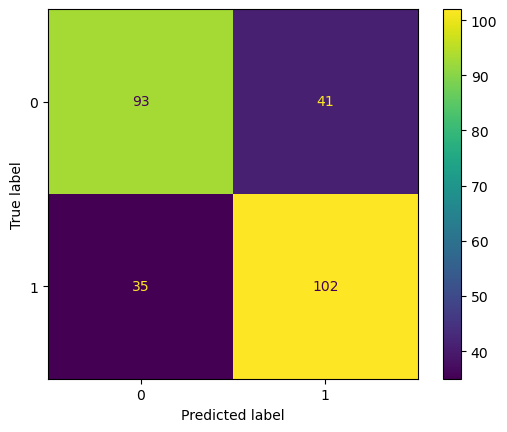

In [105]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [106]:
accuracy_score(y_test, y_predicted)

0.7195571955719557

In [107]:
recall_score(y_test, y_predicted)

0.7445255474452555

In [108]:
precision_score(y_test, y_predicted)

0.7132867132867133

In [109]:
from sklearn.metrics import brier_score_loss

In [110]:
from sklearn.svm import LinearSVC

In [111]:
from imblearn.pipeline import Pipeline

In [112]:
np.random.seed(42)
clf_svc = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LinearSVC(random_state = 42))])

In [113]:
from scipy.stats import randint, loguniform

param_distributions = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__loss': ['squared_hinge'],
    'classifier__penalty': ['l2'],
    'classifier__max_iter' : [5000, 10000],
    'classifier__dual': [False]
}

In [114]:
model_svc = RandomizedSearchCV(clf_svc, 
                              param_distributions = param_distributions, 
                              scoring = ['precision', 'recall', 'accuracy', 'f1', 'balanced_accuracy'],
                              n_iter = 8,
                              n_jobs = 1, 
                              cv = cv, 
                              random_state = 42, 
                              refit = 'balanced_accuracy')

In [115]:
model_svc.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': [0.1, 1, ...], 'classifier__dual': [False], 'classifier__loss': ['squared_hinge'], 'classifier__max_iter': [5000, 10000], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['precision', 'recall', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscro

In [116]:
pd.DataFrame(model_svc.cv_results_)[['rank_test_precision', 'mean_test_precision', 'std_test_precision']].sort_values(by = "rank_test_precision")

,rank_test_precision,mean_test_precision,std_test_precision
0,1,0.740286,0.029091
1,1,0.740286,0.029091
2,3,0.736501,0.029174
3,3,0.736501,0.029174
4,5,0.735943,0.028362
5,5,0.735943,0.028362
6,7,0.735933,0.028476
7,7,0.735933,0.028476


In [117]:
best_svc = model_svc.best_estimator_

In [118]:
y_pred_best = best_svc.predict(X_test)

In [119]:
y_scores = best_svc.predict(X_test)

accuracy:  0.7323131080389146
recall:  0.7318832360300251
precision:  0.7365014954271555


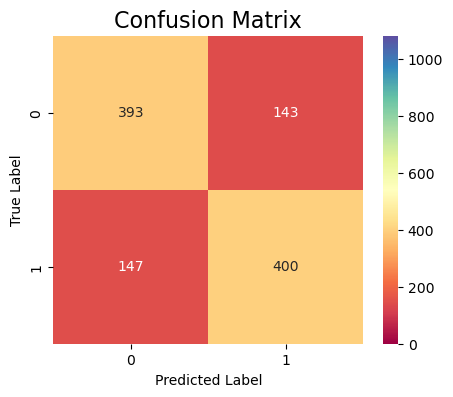

In [120]:
cv_cm(model_svc, y_train)

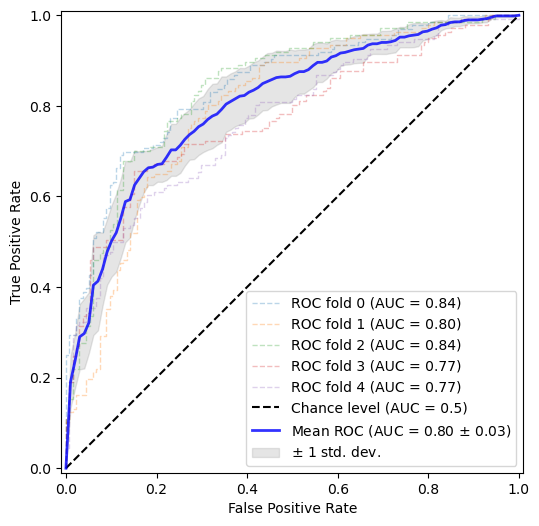

In [121]:
roc_cv(model_svc)

In [122]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

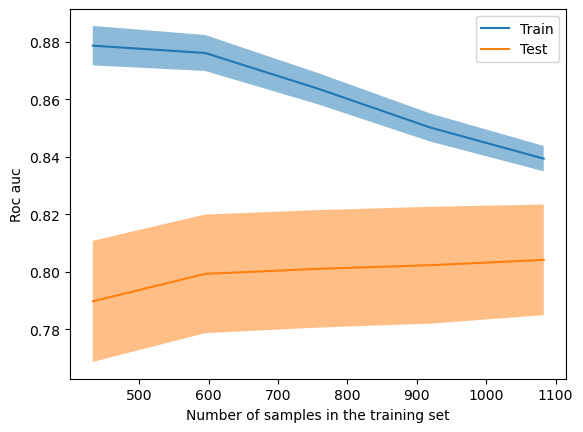

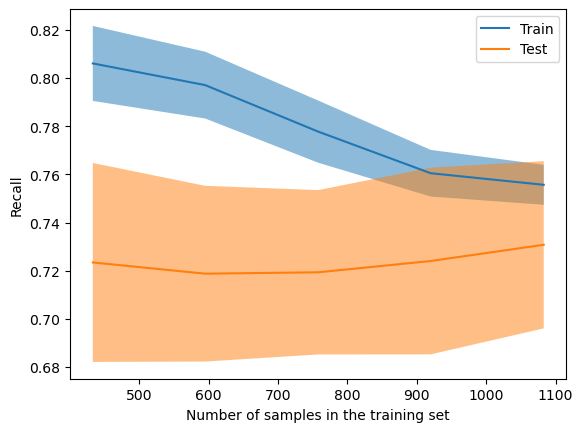

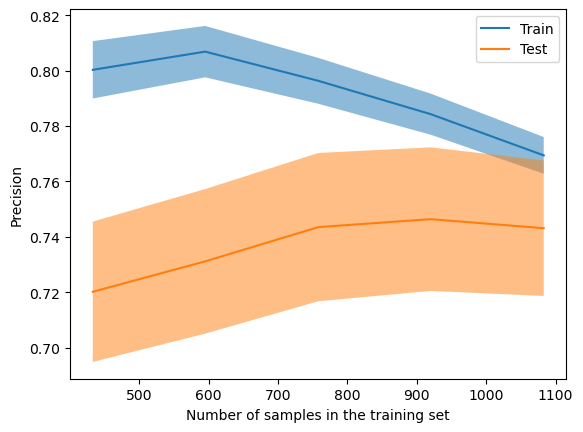

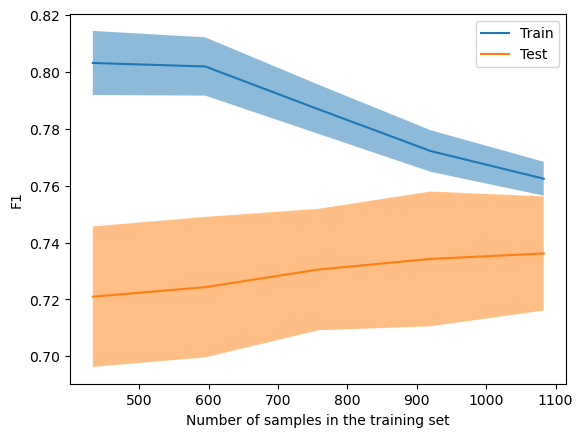

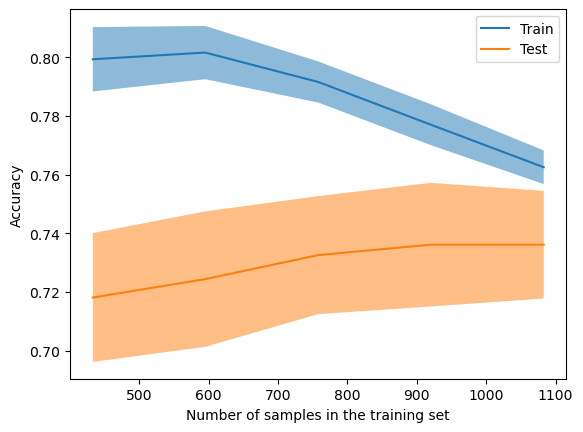

In [123]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_svc, X, y, scoring = i, cv = cv, train_sizes = train_sizes)

In [124]:
model_evaluation(best_svc)

Mean roc_auc: 0.8044857485863939
Standard deviation: 0.014774277656985925


Mean recall: 0.7356032632030914
Standard deviation: 0.02759718364662913


Mean precision: 0.7413291875822448
Standard deviation: 0.022570921199122202


Mean f1: 0.737995383600596
Standard deviation: 0.01727814299017087


Mean accuracy: 0.7366406997403306
Standard deviation: 0.01721384873408359




In [125]:
best_svc.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. Th

In [126]:
best_svc = best_svc.named_steps['classifier']

In [127]:
fitted_preprocessor = clf_svc.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.fit_transform(X_train)
X_test_transformed = fitted_preprocessor.fit_transform(X_test)

In [128]:
feature_names = fitted_preprocessor.get_feature_names_out()

In [129]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [130]:
svc_explainer = shap.Explainer(best_svc, X_train_transformed_df)
svc_shap_values = svc_explainer(X_train_transformed_df)
svc_shap_values = united_shapley(svc_shap_values)

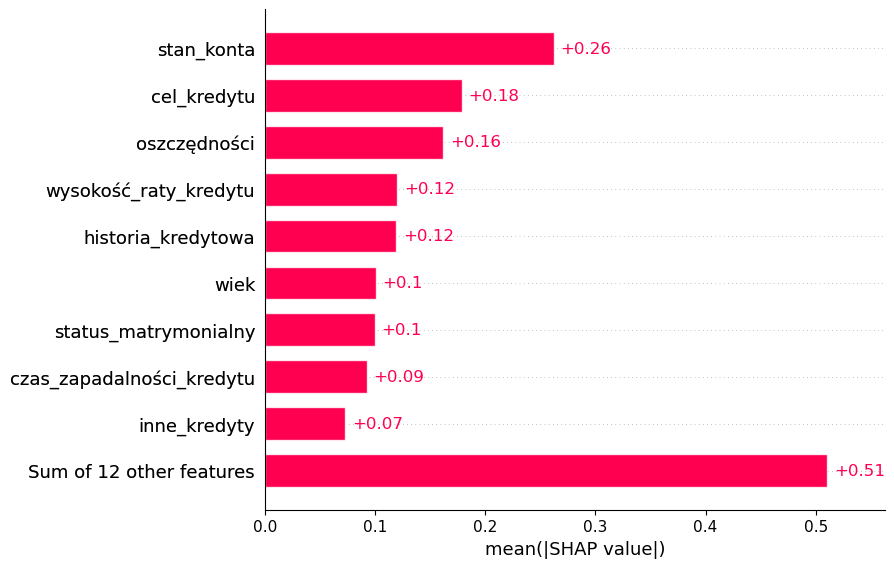

In [131]:
shap.plots.bar(svc_shap_values)

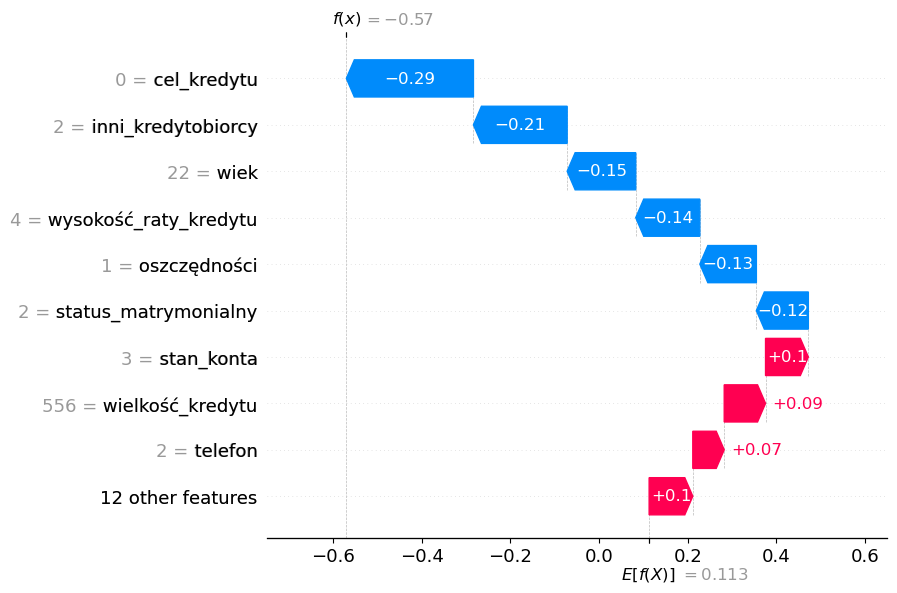

In [132]:
shap.plots.waterfall(svc_shap_values[0], max_display=10, show=True)

In [133]:
from sklearn.metrics import brier_score_loss

In [134]:
y_scores = best_svc.predict(X_test_transformed)

In [135]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.28044280442804426

In [136]:
y_predicted = best_svc.predict(X_test_transformed)

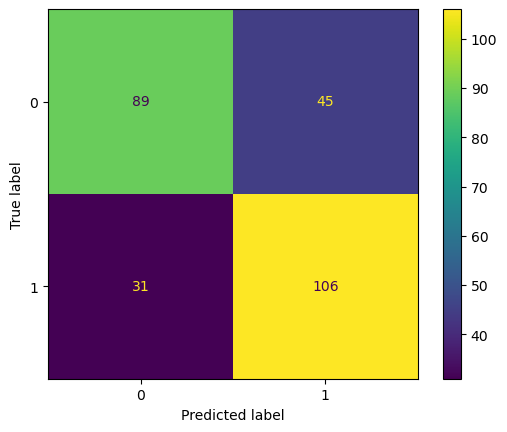

In [137]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [138]:
accuracy_score(y_test, y_predicted)

0.7195571955719557

In [139]:
recall_score(y_test, y_predicted)

0.7737226277372263

In [140]:
precision_score(y_test, y_predicted)

0.7019867549668874

In [141]:
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [142]:
rf = RandomForestClassifier(random_state = 42)

In [143]:
clf_rf = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'cat')),
    ('classifier', RandomForestClassifier(random_state = 42))])

In [144]:
param_distributions = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_split': [10, 20],
    'classifier__min_samples_leaf': [90, 100],
    'classifier__max_features': ['sqrt'],
    'classifier__criterion': ['gini', 'entropy']
}

In [145]:
model_rf = RandomizedSearchCV(clf_rf, 
                              param_distributions = param_distributions, 
                              cv = cv, 
                              n_iter = 5, 
                              n_jobs = -1, 
                              scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                              return_train_score = True, 
                              refit = 'balanced_accuracy', 
                              random_state = 42,
                             error_score = 'raise')

In [146]:
model_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [3, 5, ...], 'classifier__max_features': ['sqrt'], 'classifier__min_samples_leaf': [90, 100], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User 

In [147]:
best_rf = model_rf.best_estimator_

accuracy:  0.7281511350059736
recall:  0.7153778148457047
precision:  0.7385218161079544


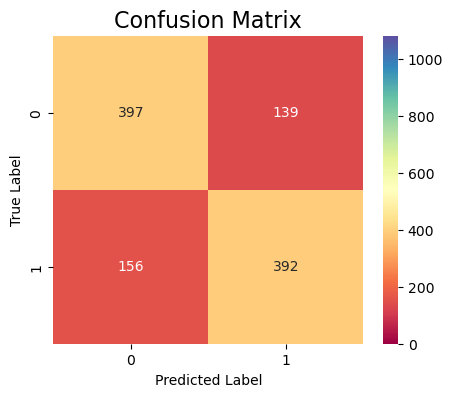

In [148]:
cv_cm(model_rf, y_train)

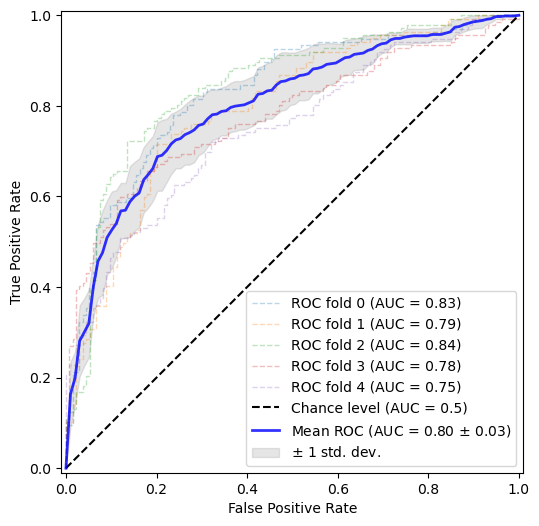

In [149]:
roc_cv(model_rf)

In [151]:
for i in evals:
     display = LearningCurveDisplay.from_estimator(best_rf, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

KeyboardInterrupt: 

In [152]:
model_evaluation(best_rf)

Mean roc_auc: 0.8018931370056829
Standard deviation: 0.01970909267115863


Mean recall: 0.7145083726921426
Standard deviation: 0.02770031122018663


Mean precision: 0.7484073545266519
Standard deviation: 0.025956806551240875


Mean f1: 0.730589146161874
Standard deviation: 0.019336782895622004


Mean accuracy: 0.7342583025830258
Standard deviation: 0.01964421859772451




In [153]:
best_rf.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [154]:
best_rf = best_rf.named_steps['classifier']

In [155]:
fitted_preprocessor = clf_rf.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [156]:
rf_explainer = shap.TreeExplainer(best_rf, X_train_transformed_df, model_output = 'probability')
rf_shap_values = rf_explainer(X_train_transformed_df)
rf_shap_values = united_shapley(rf_shap_values)

In [157]:
X_train_transformed_df.head(1)

,num__czas_zapadalności_kredytu,num__wielkość_kredytu,num__wiek,num__wielkość kredytu / czas spłaty,cat__stan_konta_1,cat__stan_konta_2,cat__stan_konta_3,cat__stan_konta_4,cat__historia_kredytowa_0,cat__historia_kredytowa_1,...,cat__praca_1,cat__praca_2,cat__praca_3,cat__praca_4,cat__liczba_osób_na_utrzymaniu_1,cat__liczba_osób_na_utrzymaniu_2,cat__telefon_1,cat__telefon_2,cat__cudzoziemiec_1,cat__cudzoziemiec_2
0,16.0,556.0,22.0,34.75,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


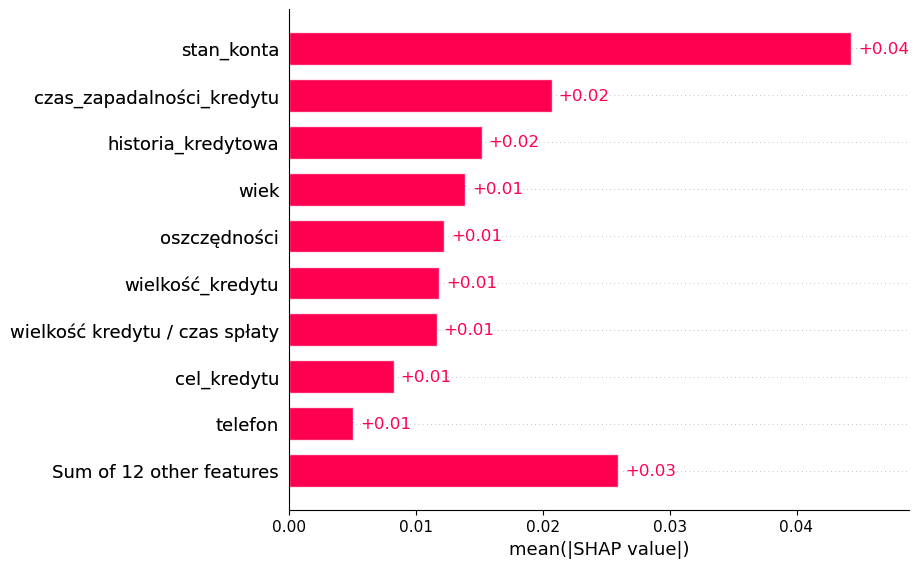

In [158]:
shap.plots.bar(rf_shap_values)

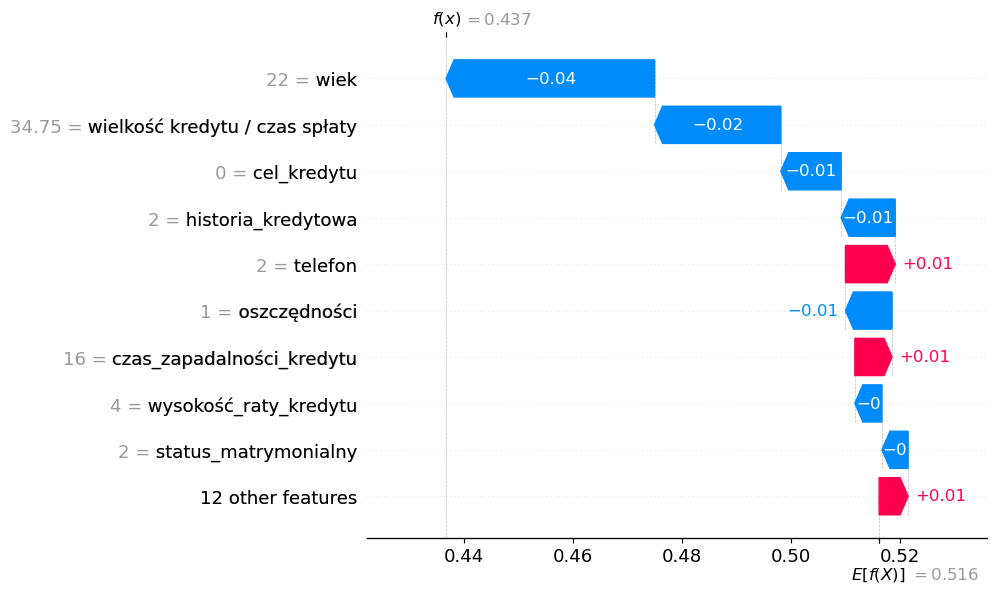

In [159]:
shap.plots.waterfall(rf_shap_values[0], max_display = 10, show=True)

In [160]:
from sklearn.metrics import brier_score_loss

In [161]:
y_scores = best_rf.predict_proba(X_test_transformed)[:, 1]

In [162]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.21338401373116786

In [163]:
y_predicted = best_rf.predict(X_test_transformed)

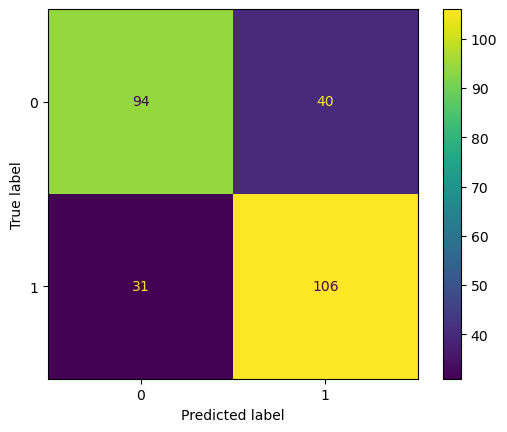

In [164]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [165]:
accuracy_score(y_test, y_predicted)

0.7380073800738007

In [166]:
recall_score(y_test, y_predicted)

0.7737226277372263

In [167]:
precision_score(y_test, y_predicted)

0.726027397260274

In [168]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [169]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC

clf_xgb = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'cat')),
                            ('classifier', XGBClassifier(random_state = 42, enable_categorical = True))])

In [170]:
param_distribution = {
    'classifier__eta' : np.linspace(0.3, 0.5, 10),
    'classifier__gamma' : randint(12, 15),
    'classifier__max_depth': randint(3, 8),
    'classifier__max_delta_step': randint(1, 10),
    'classifier__sampling_method': ['uniform'],
    'classifier__lambda' : randint(1, 5),
    'classifier__alpha': [0.0000001, 0.000001, 0.00001, 0.0001],
    'classifier__process_type': ['default'],
    'classifier__n_estimators': randint(1, 50),
    'classifier__subsample' : np.linspace(0.4, 0.6, 10)
}

In [171]:
model_xgb = RandomizedSearchCV(clf_xgb, param_distributions = param_distribution, n_iter = 10, scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], refit = 'f1_weighted', n_jobs = -1, cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42), random_state = 42, error_score = 'raise')

In [172]:
model_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__alpha': [1e-07, 1e-06, ...], 'classifier__eta': array([0.3 ..., 0.5 ]), 'classifier__gamma': <scipy.stats....0025F9BE2F620>, 'classifier__lambda': <scipy.stats....0025FD417D480>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_weighted'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across

In [173]:
best_xgb = model_xgb.best_estimator_

In [174]:
y_scores = best_xgb.predict_proba(X_test)[:, 1]

accuracy:  0.7294376173408432
recall:  0.7271226021684737
precision:  0.7347492570564561


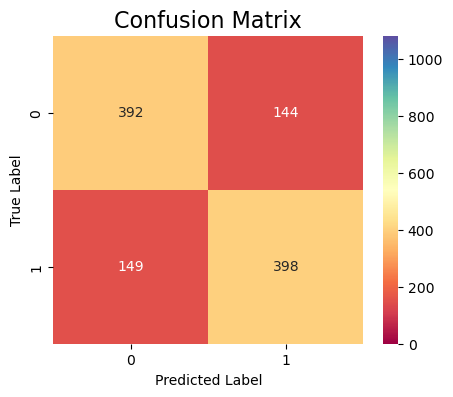

In [175]:
cv_cm(model_xgb, y_train)

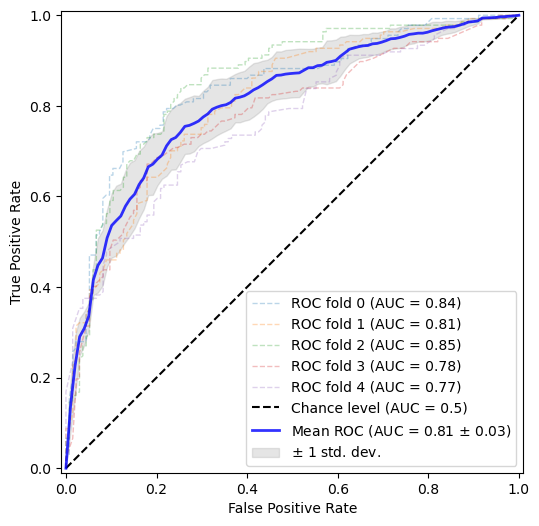

In [176]:
roc_cv(model_xgb)

In [195]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_xgb, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

ValueError: 
All the 250 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
250 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 408, in pandas_feature_info
    new_feature_types.append(_pandas_dtype_mapper[dtype.name])
                             ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
KeyError: 'object'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "C:\Users\jsmvk\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 751, in inner_f
    return func(**kwargs)
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 1787, in fit
    train_dmatrix, evals = _wrap_evaluation_matrices(
                           ~~~~~~~~~~~~~~~~~~~~~~~~~^
        missing=self.missing,
        ^^^^^^^^^^^^^^^^^^^^^
    ...<14 lines>...
        feature_types=feature_types,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 700, in _wrap_evaluation_matrices
    train_dmatrix = create_dmatrix(
        data=X,
    ...<9 lines>...
        ref=None,
    )
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\sklearn.py", line 1257, in _create_dmatrix
    return QuantileDMatrix(
        **kwargs, ref=ref, nthread=self.n_jobs, max_bin=self.max_bin
    )
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 751, in inner_f
    return func(**kwargs)
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 1719, in __init__
    self._init(
    ~~~~~~~~~~^
        data,
        ^^^^^
    ...<12 lines>...
        max_quantile_blocks=max_quantile_batches,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 1783, in _init
    it.reraise()
    ~~~~~~~~~~^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 594, in reraise
    raise exc  # pylint: disable=raising-bad-type
    ^^^^^^^^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 575, in _handle_exception
    return fn()
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 662, in <lambda>
    return self._handle_exception(lambda: int(self.next(input_data)), 0)
                                              ~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 1642, in next
    input_data(**self.kwargs)
    ~~~~~~~~~~^^^^^^^^^^^^^^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 751, in inner_f
    return func(**kwargs)
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\core.py", line 642, in input_data
    new, feature_names, feature_types = _proxy_transform(
                                        ~~~~~~~~~~~~~~~~^
        data,
        ^^^^^
    ...<2 lines>...
        self._enable_categorical,
        ^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 1695, in _proxy_transform
    df, feature_names, feature_types = _transform_pandas_df(
                                       ~~~~~~~~~~~~~~~~~~~~^
        data, enable_categorical, feature_names, feature_types
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 668, in _transform_pandas_df
    feature_names, feature_types = pandas_feature_info(
                                   ~~~~~~~~~~~~~~~~~~~^
        data, meta, feature_names, feature_types, enable_categorical
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 410, in pandas_feature_info
    _invalid_dataframe_dtype(data)
    ~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^
  File "C:\Users\jsmvk\anaconda3\Lib\site-packages\xgboost\data.py", line 373, in _invalid_dataframe_dtype
    raise ValueError(msg)
ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:stan_konta: object, historia_kredytowa: object, cel_kredytu: object, oszczędności: object, czas_zatrudnienia: object, wysokość_raty_kredytu: object, status_matrymonialny: object, inni_kredytobiorcy: object, miejsce_zamieszkania: object, najdroższa_własność: object, inne_kredyty: object, sposób_opłaty_mieszkania: object, liczba_kredytów_w_historii: object, praca: object, liczba_osób_na_utrzymaniu: object, telefon: object, cudzoziemiec: object


In [178]:
model_evaluation(best_xgb)

Mean roc_auc: 0.8021514423493429
Standard deviation: 0.019479786062939222


Mean recall: 0.7191670244740233
Standard deviation: 0.042037417856385456


Mean precision: 0.7382355985774248
Standard deviation: 0.02866957433841444


Mean f1: 0.7275395566301505
Standard deviation: 0.02367800022477859


Mean accuracy: 0.7287926745934127
Standard deviation: 0.02113963513908699




In [179]:
best_xgb = best_xgb.named_steps['classifier']

In [180]:
fitted_preprocessor = clf_xgb.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

In [181]:
feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [182]:
xgb_explainer = shap.TreeExplainer(best_xgb, X_train_transformed_df, model_output = 'probability')

In [183]:
xgb_shap_values_ohe = xgb_explainer(X_train_transformed_df)

In [184]:
xgb_shap_values_ohe = united_shapley(xgb_shap_values_ohe)

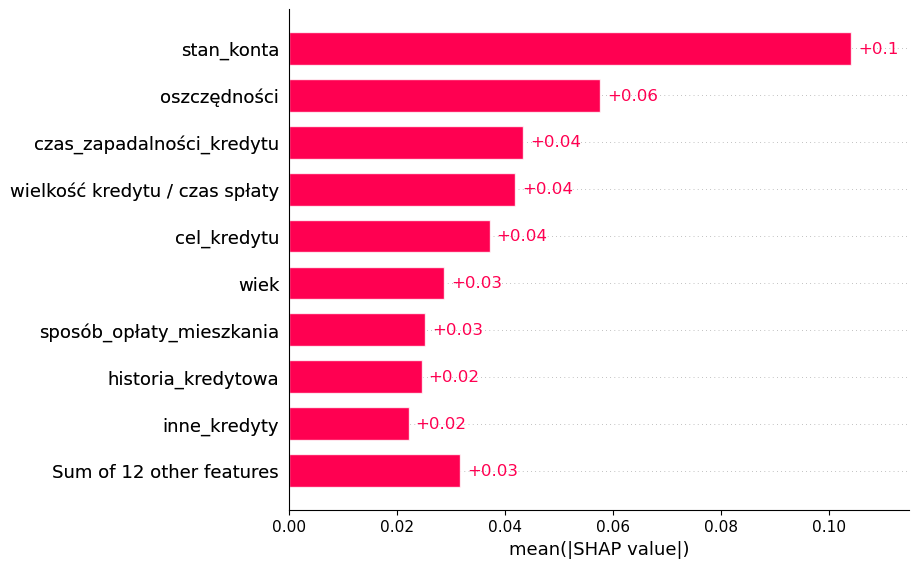

In [185]:
shap.plots.bar(xgb_shap_values_ohe)

In [186]:
X_train.head(1)

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,wielkość kredytu / czas spłaty
230,3,16,2,0,556,1,3,4,2,2,...,3,22,3,2,1,3,2,2,2,34.75


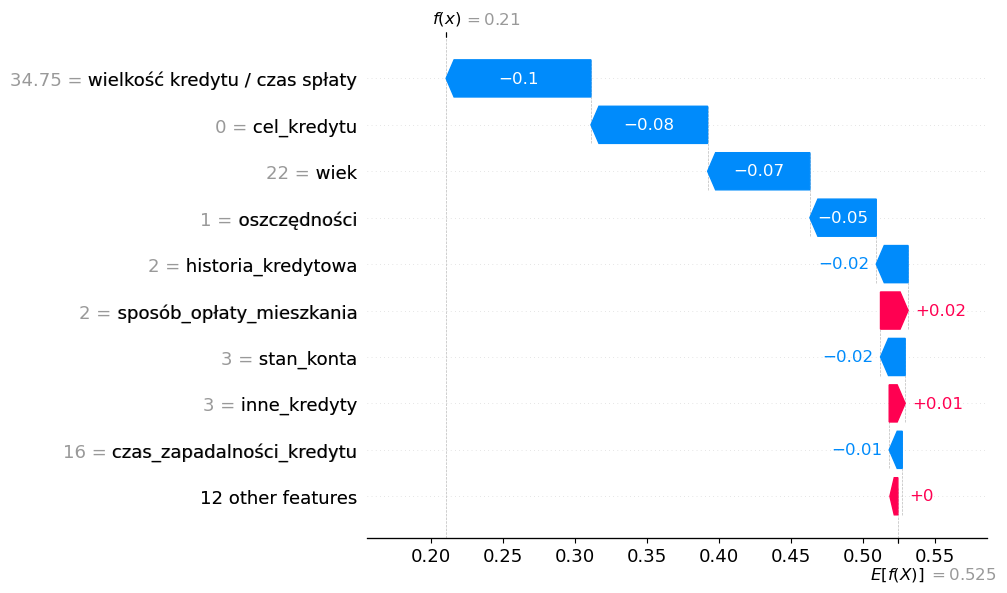

In [187]:
shap.plots.waterfall(xgb_shap_values_ohe[0], max_display = 10, show=True)

In [188]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.1806124448776245

In [189]:
y_predicted = best_xgb.predict(X_test_transformed)

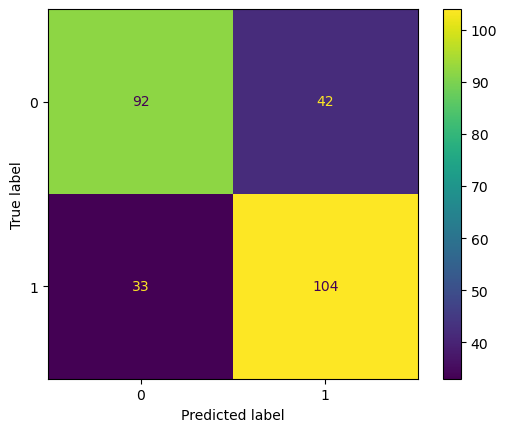

In [190]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

In [191]:
accuracy_score(y_test, y_predicted)

0.7232472324723247

In [192]:
recall_score(y_test, y_predicted)

0.7591240875912408

In [193]:
precision_score(y_test, y_predicted)

0.7123287671232876